# Quickstart: look at a pattern, then fit it with Le Bail

We read a laboratory powder pattern, look at it, and fit its cell and peak shapes.
The fit uses no atomic positions.
By the end you can read a fit's summary in the order rietx prints it, and keep the best of several Le Bail passes.

*Written by Claude Code, Anthropic's coding agent, for the rietx project.*

**You need** Python 3.11 or later and rietx 1.10 or later, which the next cell installs.
Run the cells in order from the top.
Shift+Enter runs the selected cell, and so does the ▶ button in the toolbar.
You do not need to have refined anything in rietx before.

**The data** is fluorapatite, Ca₅(PO₄)₃F, measured on a Bragg-Brentano diffractometer with a copper tube.
It is the `LabData` example from the GSAS-II tutorials and ships with rietx.
Its provenance and licence are in the repository's `tests/data/README.md`.

**Runtime** is under a minute on a laptop.

In [ ]:
%pip install rietx

In [1]:
import numpy as np

import rietx as rx
from rietx.examples import examples_dir

data = rx.read_pattern(examples_dir() / "FAP.XRA")
data

PatternData of 5753 points, 15–130.04° 2θ, median step 0.02°
  intensity:        <5753 floats 0…19693>
  sigma:            None
  excluded_regions: none
  metadata:         {source_file: 'FAP.XRA', format: 'gsas-std'}

[`rx.read_pattern`](https://rietx.org/docs/stable/reference/pattern-files.html#reading-a-pattern) recognises the format from the file.
A pattern prints as its size and range.
[`sigma`](https://rietx.org/docs/stable/reference/pattern-files.html#intensities-and-esds) reads `None` because the file has no esd column, so the fit weights each point by √y.

## Look before fitting

[Plot the pattern](https://rietx.org/docs/stable/reference/data.html#plotting-a-pattern) before any model touches it.

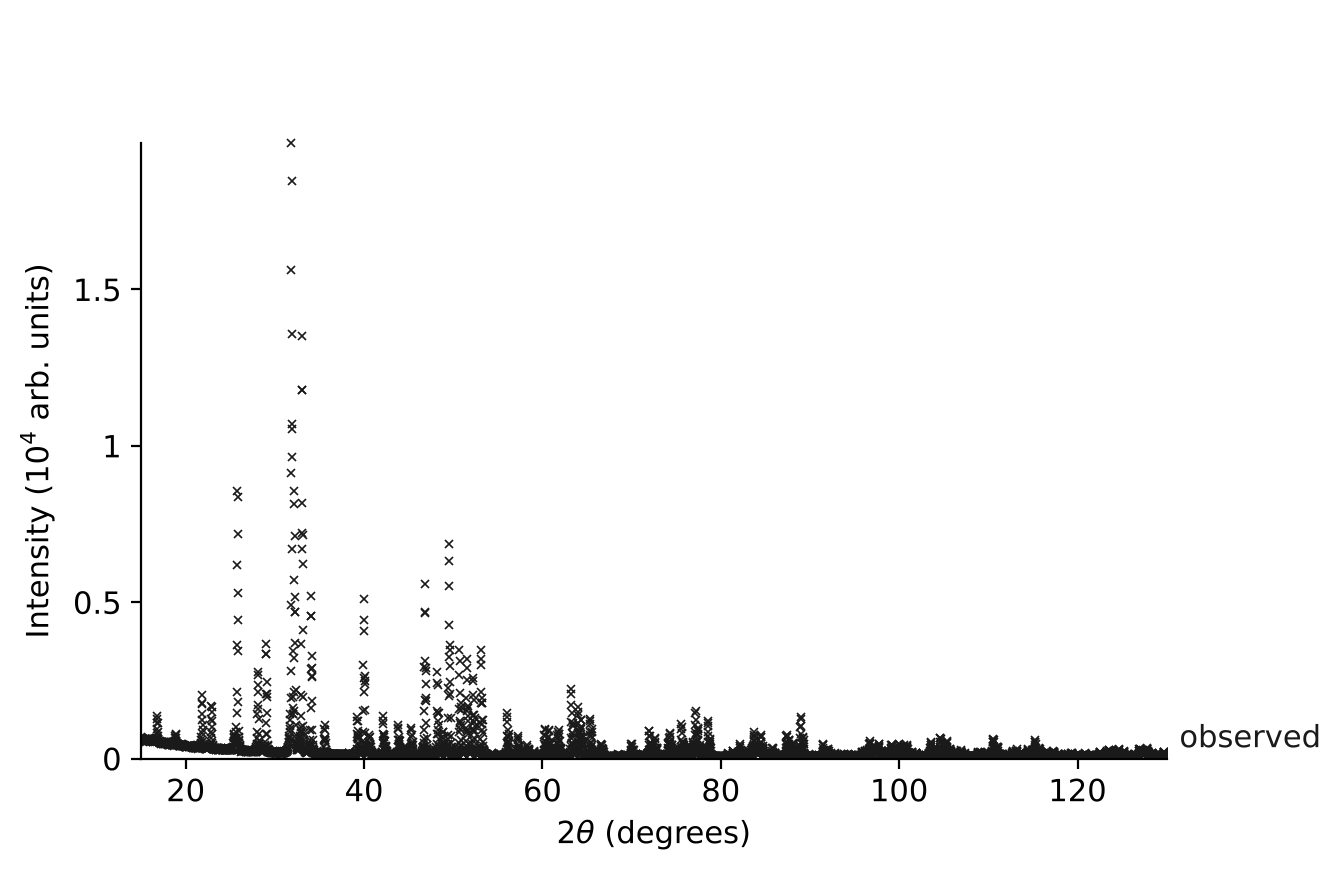

In [2]:
data.plot()

The peaks are sharp and the background is low and smooth.
Nothing in the scan looks like a second phase or an amorphous hump, so one phase is a fair start.

[`rx.diagnose`](https://rietx.org/docs/stable/reference/pattern-diagnostics.html) measures the pattern with no model.
Pass the Cu Kα1 wavelength so it can screen for Kβ and tungsten Lα lines.

In [3]:
diag = rx.diagnose(data, wavelength=1.5406)
diag

PatternDiagnostics of 5753 points, 15–130.04° 2θ
  checked on every pattern
    signal_cutoffs:       none
    steps_per_fwhm:       4.65
    n_peaks_measured:     76
    contamination:        none
    signal_to_background: 146
  matters on some instruments
    dead_channels:        not checked (no measured σ)
    coverage_plateau:     not checked (no measured σ)
    coverage_regions:     not checked (no measured σ)
    air_scatter_gain:     0.745
    amorphous_hump_score: 0.162
  rietx's own measurements
    baseline_lambda:      10000
    noise_sigma_median:   12.0
    peak_fraction:        0.524
    n_peaks:              97
    peak_density_per_deg: 0.843

The rows print under three headings.
The first group decides how this pattern can be fitted.

- `signal_cutoffs` is `none`, so neither end of the scan falls below the level of the rest.
- `steps_per_fwhm` is below the five steps the IUCr guidelines ask for. No refinement recovers that, and the fit will report it again.
- `contamination` is `none`, so no Kβ or tungsten Lα line was found.
- `signal_to_background` compares the tallest peaks with the median background.

The second group reads `not checked` for the three checks that need a measured σ, which this file does not give.
The third group holds numbers rietx measures for its own use.
[How to check a pattern before fitting](https://rietx.org/docs/stable/guides/check.html#read-the-pattern-diagnostics) explains every row.

## Build a model

A [Le Bail fit](https://rietx.org/docs/stable/reference/refinement.html#modes) needs a cell, a space group and an instrument.
The cell and space group come from a CIF of fluorapatite shipped beside the pattern.
[`rx.Structure.from_cif`](https://rietx.org/docs/stable/reference/structure-files.html#reading-a-cif) reads it.
The CIF has atoms too. A Le Bail fit ignores them.
[`rx.Instrument.bragg_brentano`](https://rietx.org/docs/stable/reference/instrument.html#constructors) builds a laboratory instrument for Cu Kα radiation.

The background is a six-term [Chebyshev polynomial](https://rietx.org/docs/stable/reference/instrument.html#chebyshev-polynomial).
Its constant term starts at the 5th percentile of the counts, and its other five terms at zero.
Left at zero, the first Le Bail extraction would count all the background under each peak as peak intensity.
[`rx.auto_background(data).background`](https://rietx.org/docs/stable/guides/check.html#size-the-background-from-the-diagnostics) would size a penalised spline instead.
On this pattern the spline reports hundreds of correlated coefficient pairs.
They would crowd the diagnostics below.

In [4]:
structure = rx.Structure.from_cif(examples_dir() / "fluorapatite.cif")
instrument = rx.Instrument.bragg_brentano(radiation="CuKa")
instrument.background = rx.BackgroundChebyshev.with_terms(6)
c0 = float(np.percentile(data.intensity, 5))
instrument.background.coefficients[0].value = c0

ref = rx.Refinement(structure, instrument)
ref

Refinement of 1 phase: fluorapatite (P 63/m)
  mode: rietveld   backend: numpy   solver: lm
  last fit: none
  parameters: 6 of 82 vary; ref.parameters() lists every row
    path                      value  state
    instrument.background.c0  65     vary
    instrument.background.c1  0      vary
    instrument.background.c2  0      vary
    instrument.background.c3  0      vary
    instrument.background.c4  0      vary
    instrument.background.c5  0      vary

A [`Refinement`](https://rietx.org/docs/stable/reference/refinement.html#entry-points) holds the structure and the instrument.
Its `mode` is the default until a fit names another.
Only the background varies so far.
The fit's plan sets the refine flags afresh at each stage, as [About a fit](https://rietx.org/docs/stable/concepts/fit.html#the-plan) describes.

Before fitting, draw the model over the data.
Start at the high-angle end, where the peaks are weak enough to show the background.
Expect the dashed starting background to run along the lowest counts between the peaks.

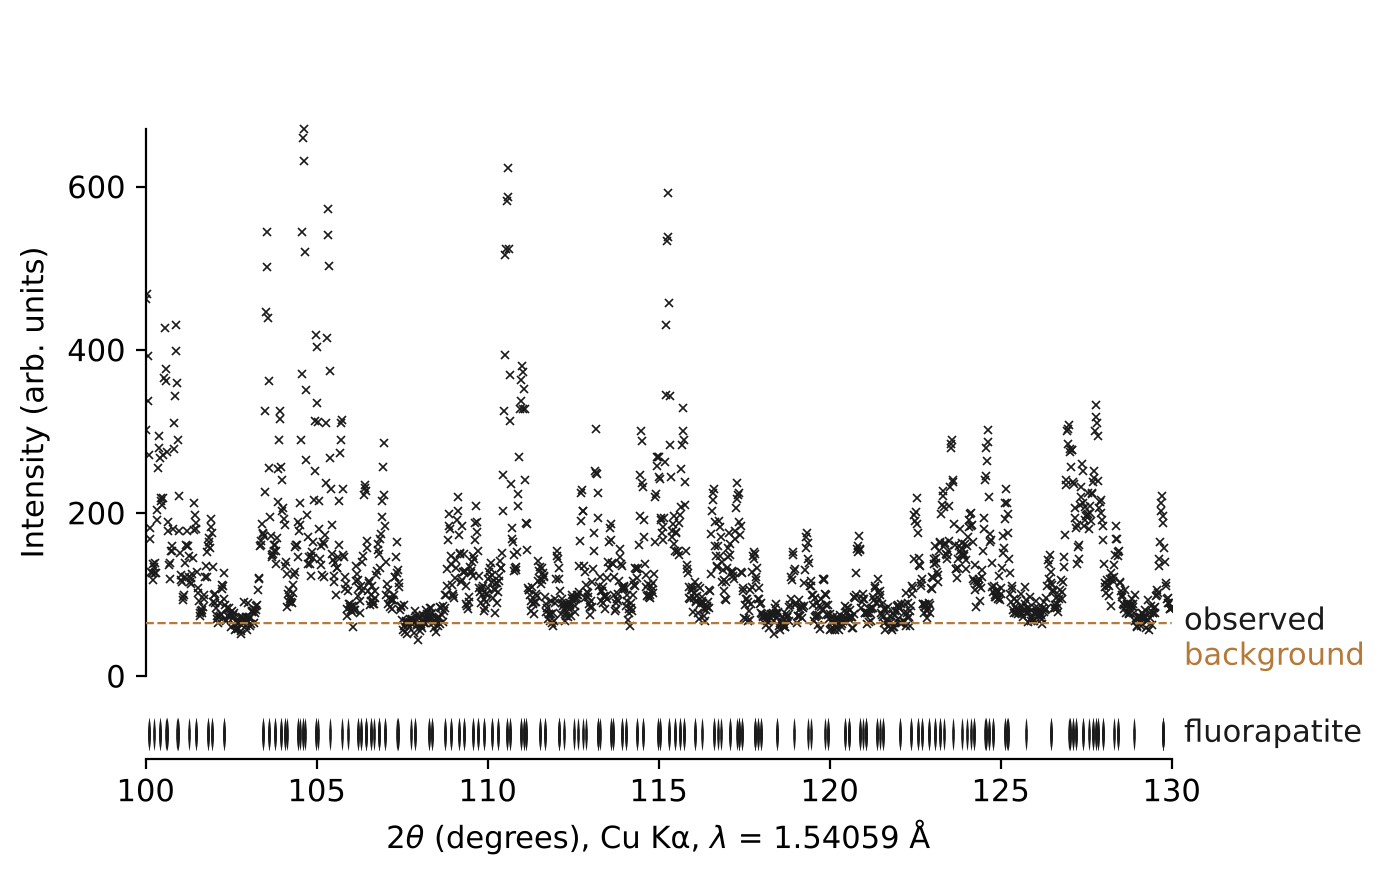

In [5]:
data.plot(model=ref, two_theta_range=(100, 130))

The dashed line is the starting background, flat at the 5th percentile of the counts.
Here it runs along the lowest counts between the peaks.
Below about 60° the counts between the peaks sit higher, as the first plot shows, so there the flat start lies under them.
The plan's first stage, `bkg`, refines all six terms to the counts before anything else moves.
The axis label names the radiation and its wavelength, read from the instrument.

Now draw the model's reflection positions under the strong peaks.
Expect a tick under every peak.

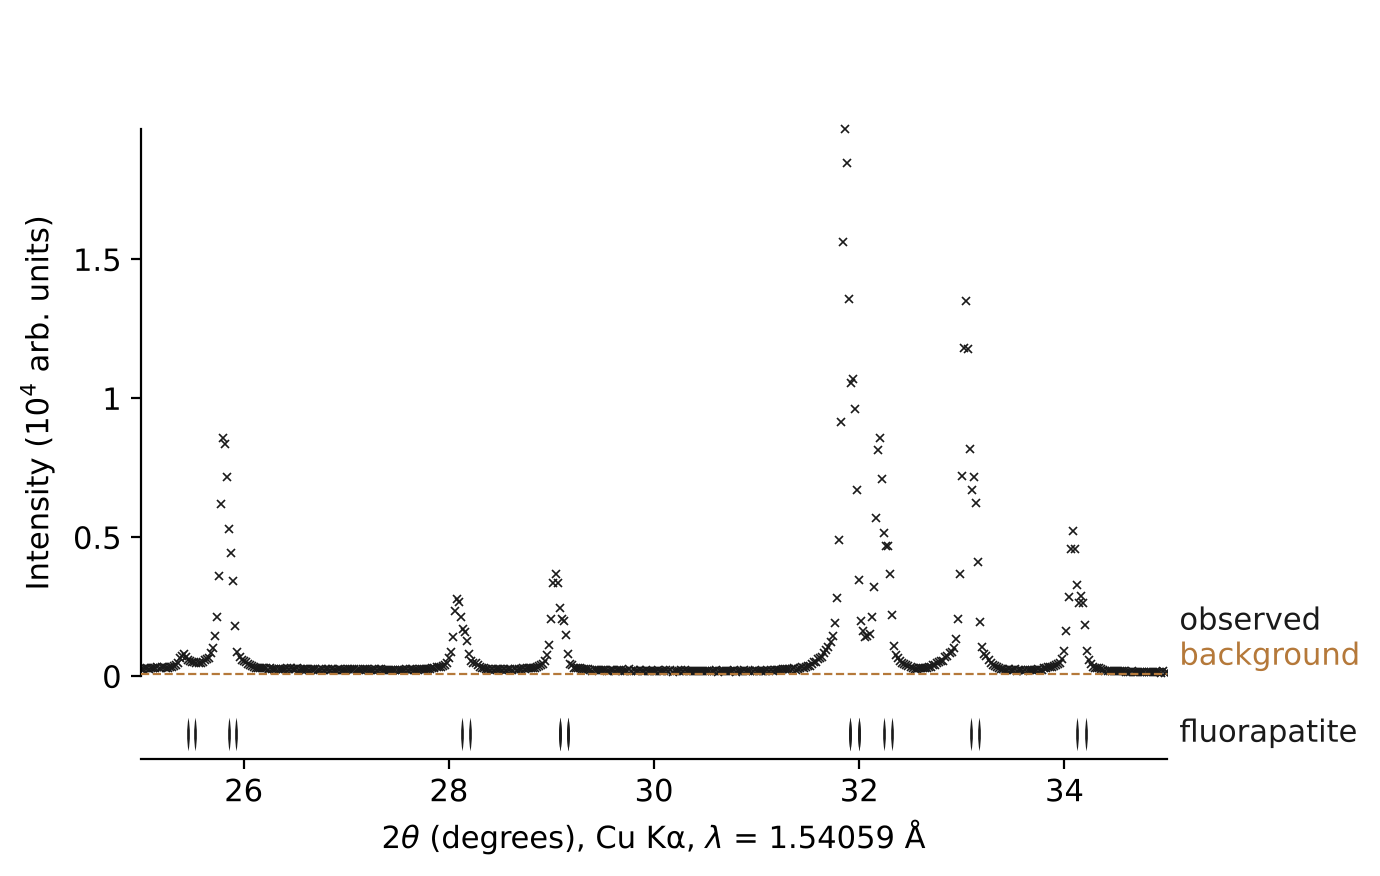

In [6]:
data.plot(model=ref, two_theta_range=(25, 35))

The ticks include the Kα2 line of each reflection, so most peaks have a pair.
Each pair sits slightly to the right of its peak, by about the same angle across this range.
A gap that is the same at every angle is a zero shift, and the fit's `zero` stage corrects it.
A gap that grows with 2θ means the starting cell or the wavelength is wrong.
Least squares moves a tick only while it still overlaps its peak.
So correct the CIF or the instrument first when a tick sits a peak width or more from its peak.

## Fit

`mode="lebail"` extracts each reflection's intensity from the data.
The `profile_only` plan runs five stages, named `bkg`, `zero`, `cell`, `profile_w` and `profile`.
Each frees one more group and keeps the earlier groups free: the background, the zero shift, the cell, the Gaussian width term W, then the other width terms U, V, X and Y.
A sixth stage, [`closing`](https://rietx.org/docs/stable/reference/refinement.html#the-closing-stage), then refines all of them together.
[Plan presets](https://rietx.org/docs/stable/reference/plans.html#profile-only) draws its stages.
[`two_theta_limits`](https://rietx.org/docs/stable/guides/range.html) sets the channels the fit uses.
We stop at 130° to match the GSAS-II tutorial.

Expect the summary to report the under-sampling again.

In [7]:
LIMITS = (15, 130)
result = ref.fit(
    data,
    mode="lebail",
    plan="profile_only",
    two_theta_limits=LIMITS,
)
result

RefinementResult: converged (lebail)
  stage bkg: converged (2 evals, ftol=1e-06)
  stage zero: converged (64 evals, ftol=1e-06)
  stage cell: converged (34 evals, ftol=1e-06)
  stage profile_w: converged (14 evals, ftol=1e-06)
  stage profile: converged (10 evals, ftol=1e-06)
  stage closing: converged (9 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 1 row, 0 errors; no deliverable given, so none is printed in full
    PATTERN_UNDERSAMPLED: warning under qpa, structure, microstructure, calibration, magnetic
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  provenance: rietx 1.11.0.dev0, backend=numpy, solver=lm
  Rwp 0.0936 / Rexp 0.0560 (GoF 1.67), Rp 0.0670, χ² 2.8, DW 1.00

Read the [summary](https://rietx.org/docs/stable/reference/result.html#printing-a-result) from the top.

1. Each stage line gives its status, the residual evaluations it took and its `ftol`.
   [`ftol`](https://rietx.org/docs/stable/reference/refinement.html#stage-tolerances) is the relative fall in χ² below which the stage stops.
   The first five stages stop at `ftol=1e-06`, a looser tolerance than the solver's own, because a later stage refines their parameters again.
   The `closing` stage runs at the solver's default, and its values are the ones to quote.
   `max|Δθ|/esd` is the largest final step of any parameter in units of its own esd.
2. The [diagnostics](https://rietx.org/docs/stable/reference/result.html#diagnostics) outrank every statistic.
   The fit was not told its purpose, so each one prints as a line and a `means:` paragraph.
   The line names the code, any parameters it concerns, and the purposes it is a warning under.
   `result.diagnostics` holds each one in full, with what to do about it.
   [`PATTERN_UNDERSAMPLED`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#pattern-undersampled) is the step count from `diagnose`.
3. The agreement indices come last. Rwp compares two fits of the same data over the same channels, and says little on its own.

The table under the summary is [every refined parameter](https://rietx.org/docs/stable/reference/parameter-table.html#refined-rows) with its esd.
A Le Bail fit lists the atoms too, held at the CIF's values.
The [`at_bound`](https://rietx.org/docs/stable/concepts/correlations.html#parameters-on-a-bound) column is `true` for a parameter that ended on one of its limits, and empty for a row the fit did not vary, such as a tied or held one.

## Fit again, and keep the best pass

A Le Bail fit holds its extracted intensities fixed inside each least-squares run.
The intensities and the profile converge only by alternating, so run the plan twice more.
[Le Bail passes](https://rietx.org/docs/stable/reference/refinement.html#le-bail-passes) gives the reason.

In [8]:
second = ref.fit(
    data,
    mode="lebail",
    plan="profile_only",
    two_theta_limits=LIMITS,
)
third = ref.fit(
    data,
    mode="lebail",
    plan="profile_only",
    two_theta_limits=LIMITS,
)
ref.history

tcb8d2285  19 nodes  data=FAP.XRA
 n0000  root                   —
 n0001  stage:bkg              Rwp 1.2444
 n0002  stage:zero             Rwp 0.7183
 n0003  stage:cell             Rwp 0.7055
 n0004  stage:profile_w        Rwp 0.1873
 n0005  stage:profile          Rwp 0.0995
 n0006  stage:closing          Rwp 0.0936
 n0007  stage:bkg              Rwp 0.0948
 n0008  stage:zero             Rwp 0.0926
 n0009  stage:cell             Rwp 0.0923
 n0010  stage:profile_w        Rwp 0.0922
 n0011  stage:profile          Rwp 0.0890
 n0012  stage:closing          Rwp 0.0899
 n0013  stage:bkg              Rwp 0.0937
 n0014  stage:zero             Rwp 0.0899
 n0015  stage:cell             Rwp 0.0892
 n0016  stage:profile_w        Rwp 0.0889
 n0017  stage:profile          Rwp 0.0884
*n0018  stage:closing          Rwp 0.0896

Each stage committed a node to the refinement's [history](https://rietx.org/docs/stable/concepts/fit.html#the-history), so each pass adds six nodes and ends on a `stage:closing` node.
A later pass is not guaranteed to end lower, so the next cell keeps the lowest.
`*` marks the head, the node the working state stands at.
A node's Rwp is measured on the model compiled at the start of its stage, so it can differ slightly from the result's.

Keep the pass with the lowest Rwp, and return the working state to its node.

In [9]:
best = min([result, second, third], key=lambda r: r.statistics.rwp)
ref.checkout(best.node_id)
best

RefinementResult: converged (lebail)
  stage bkg: converged (2 evals, ftol=1e-06)
  stage zero: converged (4 evals, ftol=1e-06)
  stage cell: converged (4 evals, ftol=1e-06)
  stage profile_w: converged (6 evals, ftol=1e-06)
  stage profile: converged (7 evals, ftol=1e-06)
  stage closing: converged (9 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 2 rows, 0 errors; no deliverable given, so none is printed in full
    RESOLUTION_UNCONSTRAINED at instrument.profile.u, .v, .w: warning under microstructure, calibration
    PATTERN_UNDERSAMPLED: warning under qpa, structure, microstructure, calibration, magnetic
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  provenance: rietx 1.11.0.dev0, backend=numpy, solver=lm
  Rwp 0.0896 / Rexp 0.0560 (GoF 1.60), Rp 0.0653, χ² 2.6, DW 1.10

The kept pass carries its own diagnostics, and they differ from the first pass's.
[`RESOLUTION_UNCONSTRAINED`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#resolution-unconstrained) is new, and it names U, V and W.
It says the peak widths are not quotable until the instrument's own widths are calibrated on a standard.
Notebook 04 does that calibration.

The cell's esds are counting statistics.
They include no error in the wavelength or the zero shift.
[Checkout, branch and merge](https://rietx.org/docs/stable/reference/history.html#checkout-branch-and-merge) describes `checkout`.

## Look at the fit

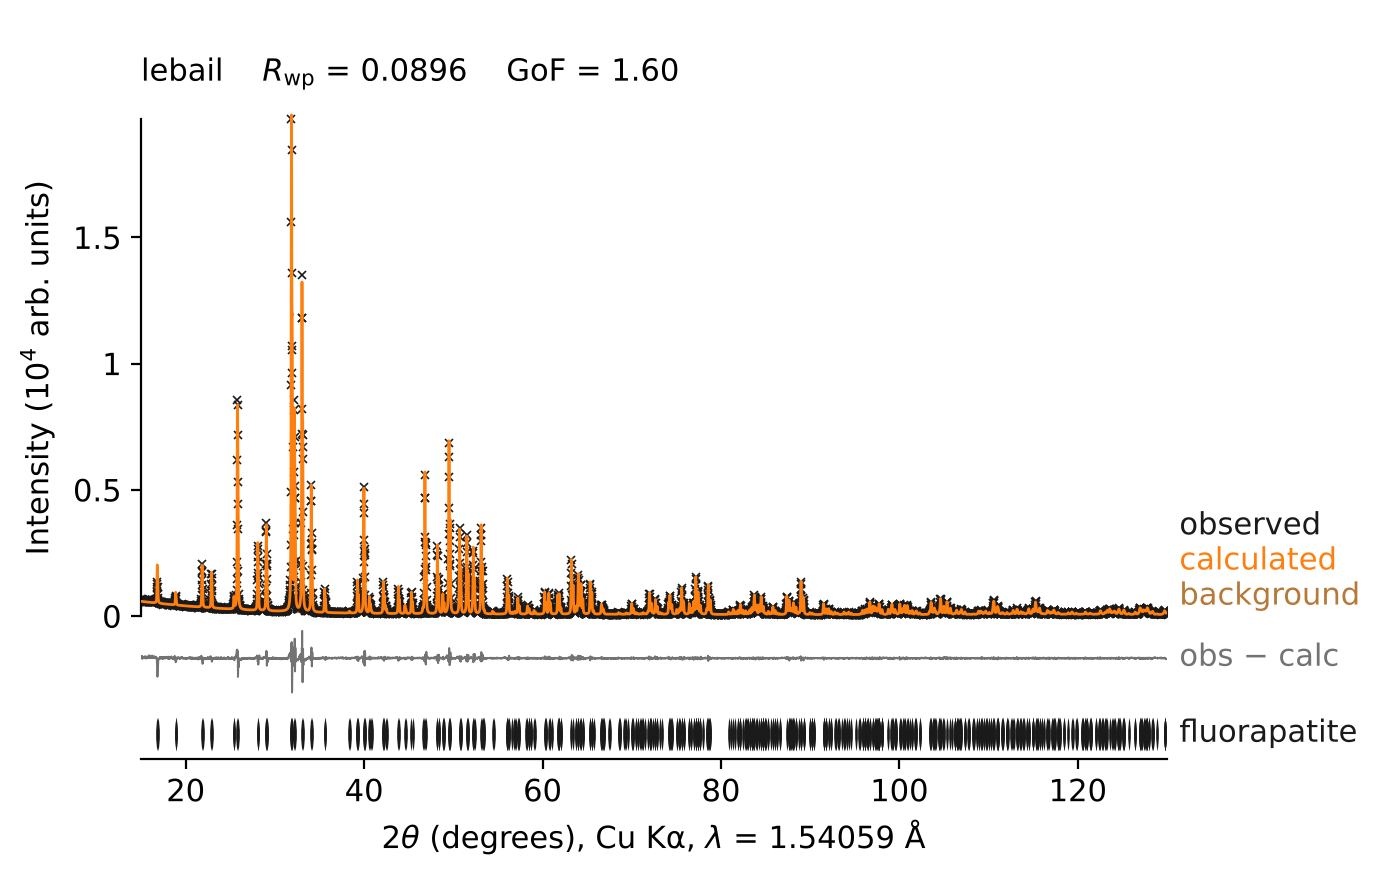

In [10]:
best.plot()

The grey trace under the pattern is the difference between the data and the model.
A good fit leaves it as noise of even width across the scan.
A wiggle at every peak means the peak shape is wrong.
A peak with no tick under it means a phase the model lacks.
Here the largest misfit sits on the strongest peaks, near 32°.
[The fit figure](https://rietx.org/docs/stable/reference/figures.html#the-fit-figure) lists every keyword `plot` takes.

Notebook 02 refines the same pattern with atoms.